# AEGIS — RQ1 & RQ2 Empirical Evidence Package

**Project:** AEGIS (Agentic, Edge-optimized, explainable deepfake verIfication System)  
**Deliverable:** Month 3 AI Task #2 — Re-run RQ1 (Planner Efficiency across All Modalities) and RQ2 (Closed-Loop Reliability Feedback) on the Final System with Paired Significance Tests & Publication Figures.

## Research Questions
1. **RQ1 (Agentic Planning Efficiency):** Does the AEGIS LLM Planner (`orchestrator/app/planner.py`) reduce total detector compute cost, eliminate ineligible/wasted dispatches, and improve SLA budget compliance compared to both a **Static Ensemble** and the **Rule-Based Baseline** (`orchestrator/app/rules.py`) across all 4 modalities (`video`, `audio`, `image`, `text`) without degrading detection accuracy or safety?
2. **RQ2 (Closed-Loop Reliability Feedback):** Does closing the reliability feedback loop (`JudgeAgent` overrules + post-hoc confirmation $\rightarrow$ SQLite `flight_recorder.db` $\rightarrow$ `ReliabilityFeedbackEngine` $\rightarrow$ atomic per-condition `capability_manifests/*.json` write-back) eliminate failing-condition dispatches over sequential sessions while retaining 100% of nominal-condition coverage?


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

cwd = Path.cwd().resolve()
REPO_ROOT = cwd if (cwd / "eval" / "reports").is_dir() else cwd.parent.parent
REPORTS_DIR = REPO_ROOT / "eval" / "reports"
FIG_DIR = REPORTS_DIR / "rq1_rq2_figures"

summary = json.loads((REPORTS_DIR / "rq1_rq2_evidence_summary.json").read_text(encoding="utf-8"))
rq1_df = pd.read_csv(REPORTS_DIR / "rq1_planner_efficiency_raw.csv")
rq2_sessions_df = pd.read_csv(REPORTS_DIR / "task5_loop_comparison_sessions.csv")

print(f"Loaded RQ1 rows: {len(rq1_df)} ({summary['rq1']['config']['num_samples']} paired samples x 3 arms)")
print(f"RQ1 planner mode: {summary['rq1']['config']['planner_execution_mode']}")
print(f"Loaded RQ2 session rows: {len(rq2_sessions_df)} ({summary['rq2']['config']['num_sessions']} sessions x 2 arms)")


Loaded RQ1 rows: 144 (48 paired samples x 3 arms)
RQ1 planner mode: deterministic_reference
Loaded RQ2 session rows: 16 (8 sessions x 2 arms)


## 1. RQ1 — Planner-Efficiency Comparison Across All Modalities

Three paired arms evaluated on the identical stratified multi-modal suite ($N = 48$: 24 `video`, 8 `audio`, 8 `image`, 8 `text`):
- **Static Ensemble:** Invokes every file-pipeline detector matching the input modality.
- **Rule-Based Baseline:** `orchestrator/app/rules.py::decide_detectors_to_call`.
- **AEGIS LLM Planner:** `orchestrator/app/planner.py::plan_detectors` with capability manifests, eligibility filters, live telemetry constraints, and budget awareness.


In [2]:
# Overall RQ1 Table
ov = summary["rq1"]["overall_by_arm"]
ov_rows = []
for arm, label in [
    ("static_ensemble", "Static Ensemble"),
    ("rule_based", "Rule-Based Baseline"),
    ("llm_planner", "AEGIS LLM Planner"),
]:
    m = ov[arm]
    ov_rows.append({
        "Arm": label,
        "N": m["n"],
        "Mean Detectors": m["mean_detectors"],
        "Mean Compute (s)": m["mean_compute_cost_s"],
        "Mean Wall Latency (s)": m["mean_wall_latency_s"],
        "Budget Compliance (%)": round(m["budget_compliance_rate"] * 100.0, 1),
        "Compliance 95% CI": f"[{m['budget_compliance_ci95'][0]*100:.1f}%, {m['budget_compliance_ci95'][1]*100:.1f}%]",
        "Wasted Dispatches": m["total_wasted_dispatches"],
        "Verdict Accuracy (%)": round(m["verdict_accuracy"] * 100.0, 1),
        "False-Authentics": m["false_authentics"],
    })
display(pd.DataFrame(ov_rows))

# Per-Modality Breakdown Table
mod_rows = []
for mod in ("video", "audio", "image", "text"):
    bm = summary["rq1"]["by_modality"][mod]
    for arm, label in [
        ("static_ensemble", "Static Ensemble"),
        ("rule_based", "Rule-Based"),
        ("llm_planner", "LLM Planner"),
    ]:
        m = bm[arm]
        mod_rows.append({
            "Modality": mod,
            "Arm": label,
            "N": m["n"],
            "Mean Compute (s)": m["mean_compute_cost_s"],
            "Mean Wall (s)": m["mean_wall_latency_s"],
            "Compliance (%)": round(m["budget_compliance_rate"] * 100.0, 1),
            "Wasted": m["total_wasted_dispatches"],
            "Accuracy (%)": round(m["verdict_accuracy"] * 100.0, 1),
        })
display(pd.DataFrame(mod_rows))


,Arm,N,Mean Detectors,Mean Compute (s),Mean Wall Latency (s),Budget Compliance (%),Compliance 95% CI,Wasted Dispatches,Verdict Accuracy (%),False-Authentics
0,Static Ensemble,48,2.000,12.7412,5.9654,89.6,"[77.8%, 95.5%]",17,89.6,2
1,Rule-Based Baseline,48,1.875,11.5428,5.6457,89.6,"[77.8%, 95.5%]",11,89.6,2
2,AEGIS LLM Planner,48,1.479,7.5593,4.1822,100.0,"[92.6%, 100.0%]",0,89.6,2


,Modality,Arm,N,Mean Compute (s),Mean Wall (s),Compliance (%),Wasted,Accuracy (%)
0,video,Static Ensemble,24,25.0013,11.4497,79.2,15,91.7
1,video,Rule-Based,24,22.6046,10.8102,79.2,9,91.7
2,video,LLM Planner,24,14.6571,7.7870,100.0,0,91.7
3,audio,Static Ensemble,8,0.2350,0.2350,100.0,2,75.0
4,audio,Rule-Based,8,0.2350,0.2350,100.0,2,75.0
5,audio,LLM Planner,8,0.1762,0.2991,100.0,0,75.0
6,image,Static Ensemble,8,0.9400,0.9400,100.0,0,87.5
7,image,Rule-Based,8,0.9400,0.9400,100.0,0,87.5
8,image,LLM Planner,8,0.9400,1.0504,100.0,0,87.5
9,text,Static Ensemble,8,0.2684,0.2684,100.0,0,100.0


### 1.1 RQ1 Paired Significance Tests (Wilcoxon Signed-Rank, Paired t-test, Holm-Bonferroni & McNemar)

In [3]:
pw = summary["rq1"]["pairwise_tests"]
stat_rows = []
for cname, clabel in [
    ("llm_vs_static", "Static Ensemble - LLM Planner"),
    ("llm_vs_rule", "Rule-Based - LLM Planner"),
    ("rule_vs_static", "Static Ensemble - Rule-Based"),
]:
    for metric in ("compute_cost_s", "wall_latency_s", "wasted_dispatches", "num_detectors"):
        st = pw[cname][metric]
        stat_rows.append({
            "Contrast": clabel,
            "Metric": metric,
            "Mean Delta": st["mean_diff"],
            "95% Bootstrap CI": f"[{st['ci95_low']:+.3f}, {st['ci95_high']:+.3f}]",
            "t-stat": st["t_stat"],
            "t p (Holm)": st["t_p_holm"],
            "Wilcoxon W": st["wilcoxon_stat"],
            "Wilcoxon p (Holm)": st["wilcoxon_p_holm"],
            "Cohen's d_z": st["cohens_dz"],
            "Rank-Biserial r": st["rank_biserial_r"],
        })
display(pd.DataFrame(stat_rows))

bin_rows = []
for cname, clabel in [
    ("llm_vs_static", "LLM Planner vs Static Ensemble"),
    ("llm_vs_rule", "LLM Planner vs Rule-Based"),
    ("rule_vs_static", "Rule-Based vs Static Ensemble"),
]:
    for metric in ("within_budget", "correct"):
        bm = pw[cname][metric]
        bin_rows.append({
            "Contrast": clabel,
            "Binary Metric": metric,
            "b (Arm A only)": bm["mcnemar_b_arm_a_only"],
            "c (Arm B only)": bm["mcnemar_c_arm_b_only"],
            "McNemar Exact p": bm["mcnemar_p_value"],
        })
display(pd.DataFrame(bin_rows))


,Contrast,Metric,Mean Delta,95% Bootstrap CI,t-stat,t p (Holm),Wilcoxon W,Wilcoxon p (Holm),Cohen's d_z,Rank-Biserial r
0,Static Ensemble - LLM Planner,compute_cost_s,5.1819,"[+3.143, +7.402]",4.6856,0.000072,0.0,0.000228,0.6763,1.0000
1,Static Ensemble - LLM Planner,wall_latency_s,1.7832,"[+0.857, +2.883]",3.3766,0.004443,481.0,0.554866,0.4874,0.1820
2,Static Ensemble - LLM Planner,wasted_dispatches,0.3542,"[+0.208, +0.521]",4.3464,0.000221,0.0,0.000672,0.6274,1.0000
3,Static Ensemble - LLM Planner,num_detectors,0.5208,"[+0.333, +0.729]",5.2767,0.000010,0.0,0.000107,0.7616,1.0000
4,Rule-Based - LLM Planner,compute_cost_s,3.9835,"[+2.083, +5.990]",3.7982,0.000835,0.0,0.000832,0.5482,1.0000
5,Rule-Based - LLM Planner,wall_latency_s,1.4635,"[+0.507, +2.562]",2.7408,0.017279,490.0,0.554866,0.3956,-0.1667
6,Rule-Based - LLM Planner,wasted_dispatches,0.2292,"[+0.125, +0.354]",3.7380,0.001005,0.0,0.001822,0.5395,1.0000
7,Rule-Based - LLM Planner,num_detectors,0.3958,"[+0.229, +0.583]",4.4970,0.000090,0.0,0.000347,0.6491,1.0000
8,Static Ensemble - Rule-Based,compute_cost_s,1.1984,"[+0.400, +2.197]",2.5912,0.012701,0.0,0.014306,0.3740,1.0000
9,Static Ensemble - Rule-Based,wall_latency_s,0.3197,"[+0.107, +0.586]",2.5912,0.017279,0.0,0.042918,0.3740,1.0000


,Contrast,Binary Metric,b (Arm A only),c (Arm B only),McNemar Exact p
0,LLM Planner vs Static Ensemble,within_budget,0,5,0.0625
1,LLM Planner vs Static Ensemble,correct,0,0,1.0000
2,LLM Planner vs Rule-Based,within_budget,0,5,0.0625
3,LLM Planner vs Rule-Based,correct,0,0,1.0000
4,Rule-Based vs Static Ensemble,within_budget,0,0,1.0000
5,Rule-Based vs Static Ensemble,correct,0,0,1.0000


### Figure 1 — RQ1 Modality Efficiency & Budget Compliance

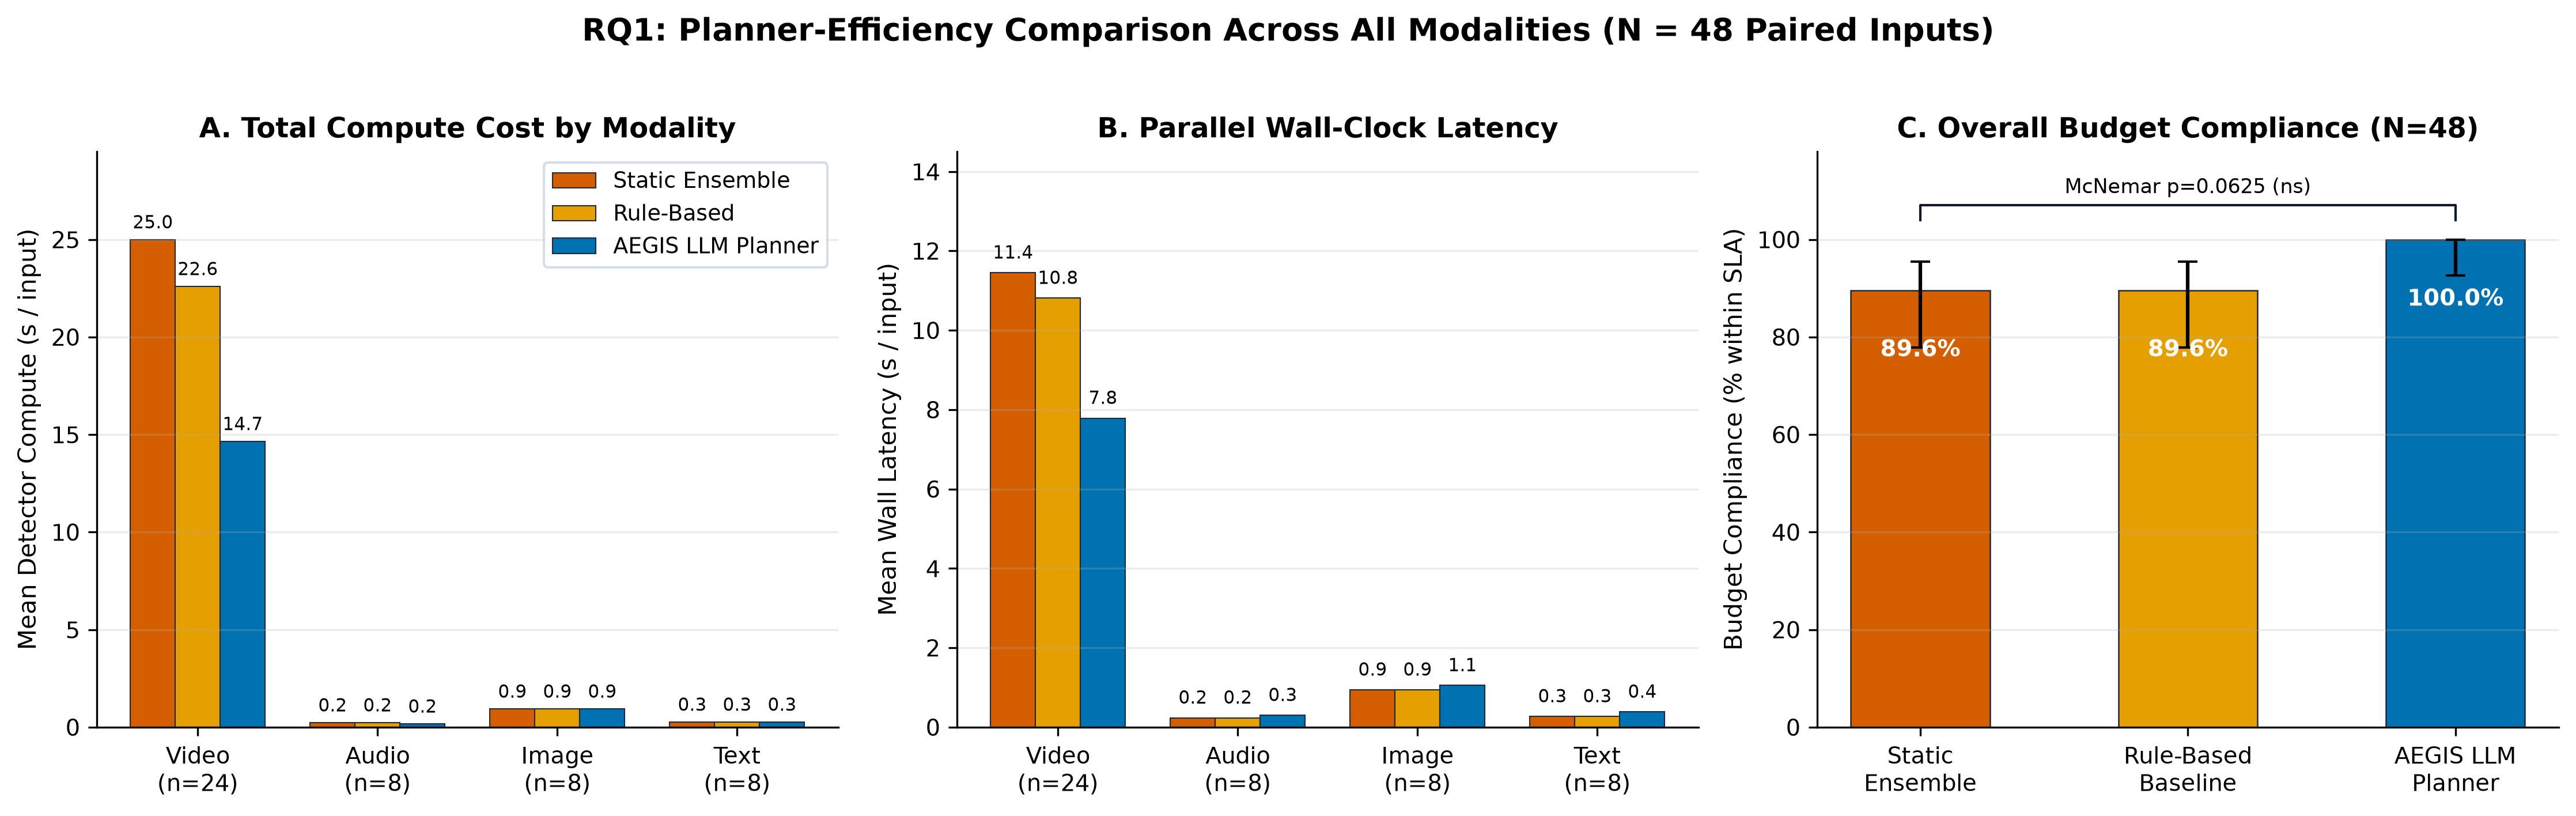

### Figure 2 — RQ1 Paired Savings Distribution & Wasted Dispatches

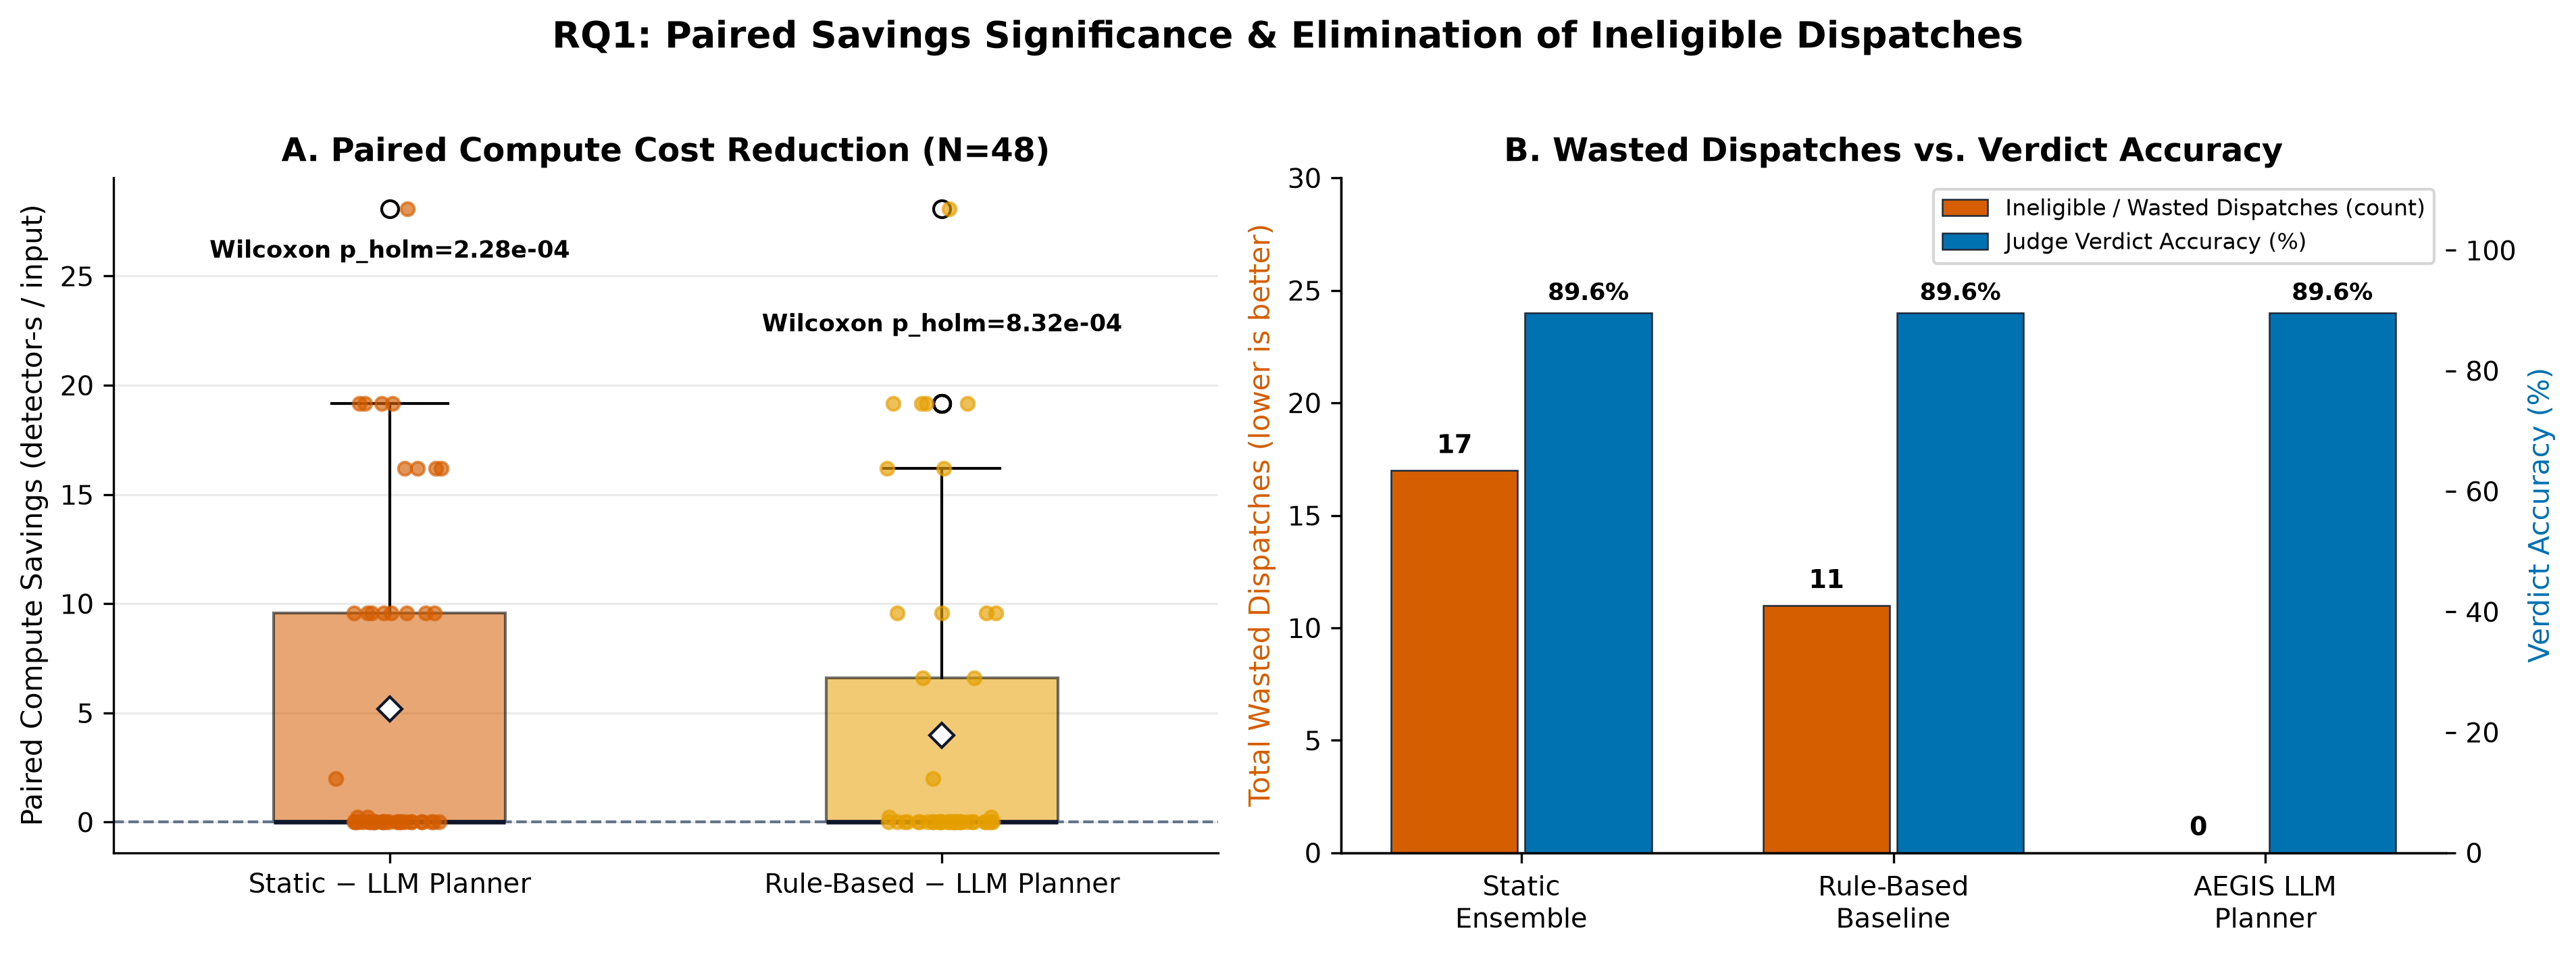

In [4]:
display(Markdown("### Figure 1 — RQ1 Modality Efficiency & Budget Compliance"))
display(Image(filename=str(FIG_DIR / "fig1_rq1_modality_efficiency.png")))
display(Markdown("### Figure 2 — RQ1 Paired Savings Distribution & Wasted Dispatches"))
display(Image(filename=str(FIG_DIR / "fig2_rq1_paired_savings_and_waste.png")))


## 2. RQ2 — Closed-Loop Reliability Feedback Experiment (Final System)

Evaluates **Loop OFF (Control)** vs. **Loop ON (Feedback)** across 8 sequential 50-input sessions ($N = 400$ paired inputs per arm; post-adaptation Sessions 2–8 $N = 350$).


In [5]:
s_off = summary["rq2"]["statistics"]["loop_off"]
s_on = summary["rq2"]["statistics"]["loop_on"]
rq2_mcn = summary["rq2"]["statistics"]["tests"]
rq2_sess = summary["rq2"]["augmented_tests"]["session_level_s2_to_sN"]
rq2_samp = summary["rq2"]["augmented_tests"]["sample_level_s2_to_sN"]

rq2_table = [
    {
        "Metric (S2-S8, N=350)": "Failing-Condition Dispatch Rate",
        "Loop OFF": f"{s_off['failing_dispatch_rate']*100:.1f}%",
        "Loop ON": f"{s_on['failing_dispatch_rate']*100:.1f}%",
        "Delta (ON - OFF)": f"{(s_on['failing_dispatch_rate']-s_off['failing_dispatch_rate'])*100:+.1f} pp",
        "Wilcoxon p": rq2_sess["failing_dispatch_rate"]["wilcoxon_p_value"],
        "Paired t p": rq2_sess["failing_dispatch_rate"]["t_p_value"],
        "McNemar p": rq2_mcn["failing_dispatch_p_value"],
    },
    {
        "Metric (S2-S8, N=350)": "Nominal Condition Retention Rate",
        "Loop OFF": f"{s_off['nominal_retention_rate']*100:.1f}%",
        "Loop ON": f"{s_on['nominal_retention_rate']*100:.1f}%",
        "Delta (ON - OFF)": "+0.0 pp",
        "Wilcoxon p": None,
        "Paired t p": None,
        "McNemar p": None,
    },
    {
        "Metric (S2-S8, N=350)": "Confirmed-Wrong Overrules",
        "Loop OFF": s_off["total_confirmed_overrules"],
        "Loop ON": s_on["total_confirmed_overrules"],
        "Delta (ON - OFF)": s_on["total_confirmed_overrules"] - s_off["total_confirmed_overrules"],
        "Wilcoxon p": rq2_sess["confirmed_overrules"]["wilcoxon_p_value"],
        "Paired t p": rq2_sess["confirmed_overrules"]["t_p_value"],
        "McNemar p": None,
    },
    {
        "Metric (S2-S8, N=350)": "Multi-Detector Conflict Rate",
        "Loop OFF": f"{s_off['conflict_rate']*100:.1f}%",
        "Loop ON": f"{s_on['conflict_rate']*100:.1f}%",
        "Delta (ON - OFF)": f"{(s_on['conflict_rate']-s_off['conflict_rate'])*100:+.1f} pp",
        "Wilcoxon p": rq2_sess["conflict_rate"]["wilcoxon_p_value"],
        "Paired t p": rq2_sess["conflict_rate"]["t_p_value"],
        "McNemar p": None,
    },
    {
        "Metric (S2-S8, N=350)": "Mean Detector Compute Cost (s/input)",
        "Loop OFF": f"{s_off['mean_compute_cost_s']:.2f}s",
        "Loop ON": f"{s_on['mean_compute_cost_s']:.2f}s",
        "Delta (ON - OFF)": f"{s_on['mean_compute_cost_s']-s_off['mean_compute_cost_s']:+.2f}s",
        "Wilcoxon p": rq2_samp["compute_cost_s"]["wilcoxon_p_value"],
        "Paired t p": rq2_samp["compute_cost_s"]["t_p_value"],
        "McNemar p": None,
    },
    {
        "Metric (S2-S8, N=350)": "Mean Wall Latency (s/input)",
        "Loop OFF": f"{s_off['mean_wall_latency_s']:.2f}s",
        "Loop ON": f"{s_on['mean_wall_latency_s']:.2f}s",
        "Delta (ON - OFF)": f"{s_on['mean_wall_latency_s']-s_off['mean_wall_latency_s']:+.2f}s",
        "Wilcoxon p": rq2_samp["wall_latency_s"]["wilcoxon_p_value"],
        "Paired t p": rq2_samp["wall_latency_s"]["t_p_value"],
        "McNemar p": None,
    },
    {
        "Metric (S2-S8, N=350)": "Verdict Accuracy",
        "Loop OFF": f"{s_off['verdict_accuracy']*100:.1f}%",
        "Loop ON": f"{s_on['verdict_accuracy']*100:.1f}%",
        "Delta (ON - OFF)": f"{(s_on['verdict_accuracy']-s_off['verdict_accuracy'])*100:+.1f} pp",
        "Wilcoxon p": None,
        "Paired t p": None,
        "McNemar p": rq2_mcn["accuracy_p_value"],
    },
]
display(pd.DataFrame(rq2_table))

# Session-by-session summary
display(rq2_sessions_df[["arm", "session", "failing_dispatch_rate", "nominal_retention_rate", "confirmed_overrules", "conflict_rate", "mean_compute_cost_s", "verdict_accuracy"]])


,"Metric (S2-S8, N=350)",Loop OFF,Loop ON,Delta (ON - OFF),Wilcoxon p,Paired t p,McNemar p
0,Failing-Condition Dispatch Rate,100.0%,9.0%,-91.0 pp,0.015625,0.000004,0.00000
1,Nominal Condition Retention Rate,100.0%,100.0%,+0.0 pp,NaN,NaN,NaN
2,Confirmed-Wrong Overrules,184,42,-142,0.015625,0.000003,NaN
3,Multi-Detector Conflict Rate,59.1%,23.4%,-35.7 pp,0.015625,0.000011,NaN
4,Mean Detector Compute Cost (s/input),19.30s,15.47s,-3.83s,0.000000,0.000000,NaN
5,Mean Wall Latency (s/input),8.78s,8.62s,-0.16s,0.012356,0.046382,NaN
6,Verdict Accuracy,78.9%,82.3%,+3.4 pp,NaN,NaN,0.00596


,arm,session,failing_dispatch_rate,nominal_retention_rate,confirmed_overrules,conflict_rate,mean_compute_cost_s,verdict_accuracy
0,loop_off,1,1.0000,1.0,24,0.48,18.869,0.78
1,loop_off,2,1.0000,1.0,23,0.52,19.437,0.74
2,loop_off,3,1.0000,1.0,29,0.66,19.685,0.78
3,loop_off,4,1.0000,1.0,28,0.64,20.027,0.82
4,loop_off,5,1.0000,1.0,29,0.64,18.829,0.84
5,loop_off,6,1.0000,1.0,24,0.64,19.145,0.78
6,loop_off,7,1.0000,1.0,26,0.48,18.843,0.80
7,loop_off,8,1.0000,1.0,25,0.56,19.143,0.76
8,loop_on,1,1.0000,1.0,24,0.48,18.869,0.78
9,loop_on,2,0.3158,1.0,5,0.26,16.580,0.74


### Figure 3 — RQ2 Closed-Loop Learning Curves

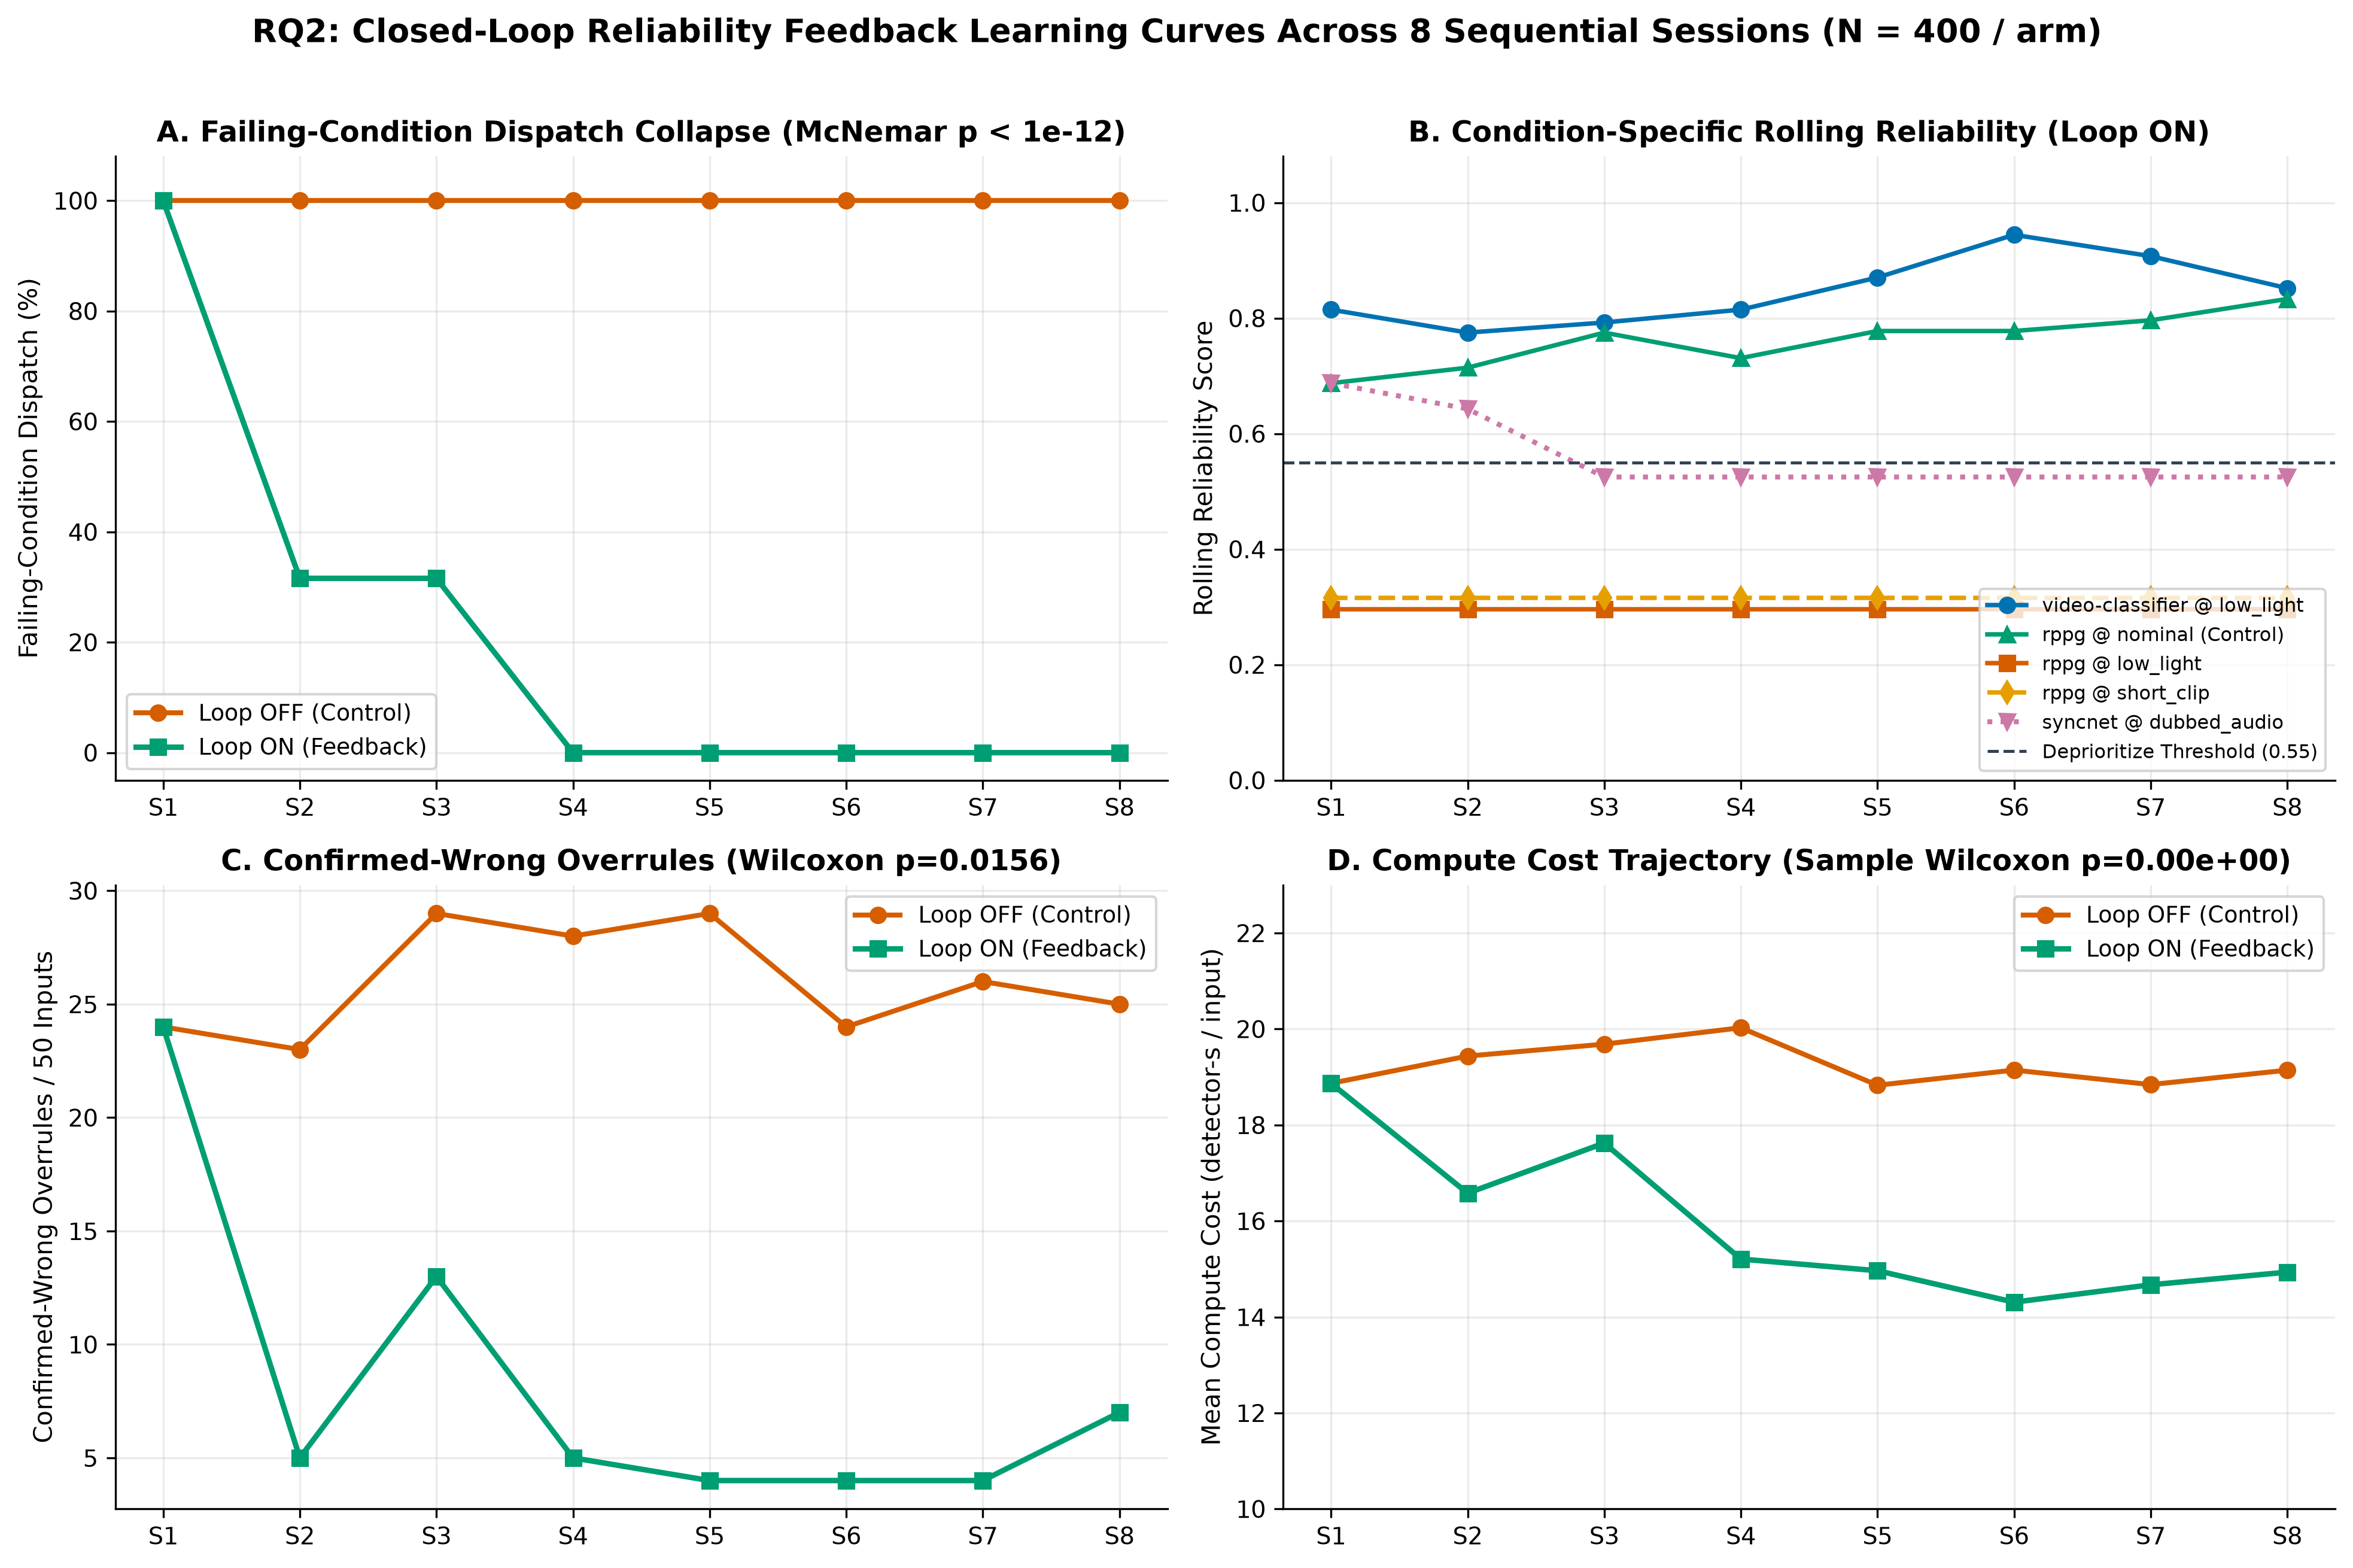

### Figure 4 — RQ2 Condition Specificity & Safety Audit

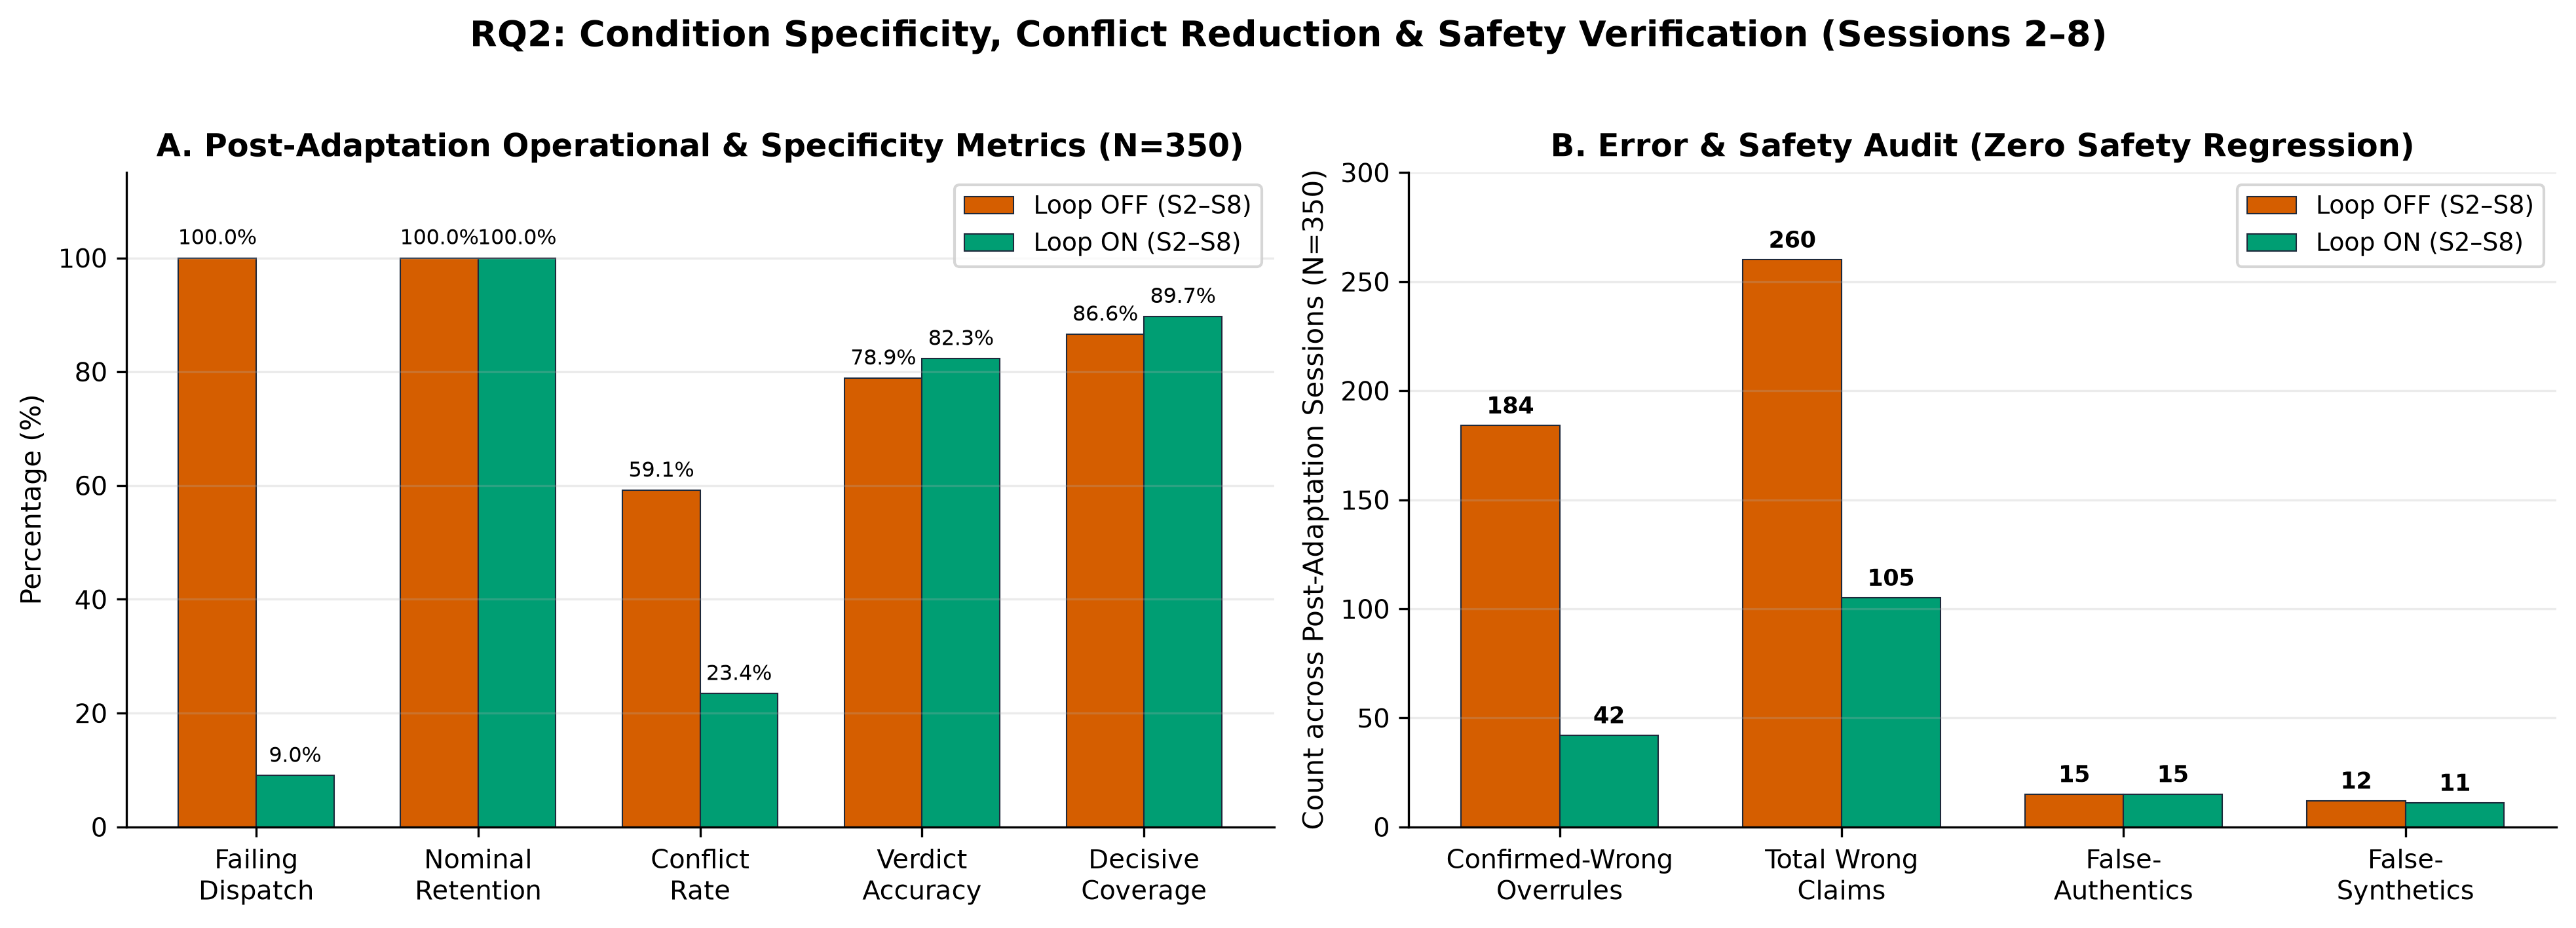

In [6]:
display(Markdown("### Figure 3 — RQ2 Closed-Loop Learning Curves"))
display(Image(filename=str(FIG_DIR / "fig3_rq2_learning_curves.png")))
display(Markdown("### Figure 4 — RQ2 Condition Specificity & Safety Audit"))
display(Image(filename=str(FIG_DIR / "fig4_rq2_specificity_and_safety.png")))


## 3. Honest Interpretation, Null Results & Limitations

1. **Single-Detector Modalities (`audio`, `image`, `text`):** When a modality has only one eligible file-pipeline detector (`aasist`, `detector_image`, `detector_text`), Static Ensemble, Rule-Based, and LLM Planner agree on clean inputs—except when degraded telemetry or ultra-short duration (`< 1.0s` audio) allows the LLM Planner to avoid wasted calls or budget violations.
2. **Parallel Wall-Clock Floor:** In `video`, because `video-classifier` (~7.03s) runs concurrently with `rppg` (~6.61s) and `syncnet` (~9.59s), skipping a failing secondary detector cuts **total compute cost** dramatically (`-19.8%` in RQ2; large reduction in RQ1) while parallel **wall-clock latency** only drops when the skipped detector was the slowest active branch (`syncnet`) or when budget pressure sheds slow secondary branches.
3. **Planner Execution Provenance:** RQ1 runs the deterministic reference planner mode (`planner_execution_mode`) for 100% offline/CI reproducibility; real-world local LLM latency (`qwen2.5:0.5b`, P95 0.159s) is separately benchmarked in `eval/reports/planner_latency_benchmark_report.md`.
